# 02 · Xử lý dữ liệu fine-tune

Từ dữ liệu các nguồn (01) tạo ra bộ **train / val** sạch cho BGE-M3:

1. Tải / trích nguồn (bỏ qua nếu đã có)
2. Chuẩn hoá + gióng v5 cho từng nguồn → `data/processed/finetune/<nguồn>/aligned.jsonl`
3. Chọn tier/temporal → khử trùng → loại câu gần trùng benchmark → chia train/val **theo Điều** → giới hạn câu sinh ≤ 40%
4. Kiểm chứng + đọc mẫu
5. (GPU) Đào hard negative → ghép `train.jsonl`, `val.jsonl`

Toàn bộ logic nằm trong `labor_rag/finetune/` (`fetch_hf_sources`, `sources`, `align`, `build_dataset`, `mine_negatives`, `assemble_dataset`) và có test ở `tests/test_finetune_build.py`; notebook chỉ điều phối và hiển thị.
Quy tắc chi tiết: `docs/FINETUNE_DATA.md`.

In [1]:
import json
import random
import re
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "labor_rag" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from labor_rag.config import (
    EVALUATION_DIR, FINETUNE_MERGED_DIR, FINETUNE_SOURCES, LAO_DONG_DIR,
    finetune_raw_dir, finetune_source_dir,
)

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

# Bảng màu giống notebooks/dataset_analysis.ipynb
INK, INK_SECOND, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECOND, "text.color": INK, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "grid.color": GRID, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def stacked_barh(df, title, colors=CAT, figsize=(9, 4)):
    """Horizontal stacked bars, one row per index value, columns as segments."""
    ax = df.plot(kind="barh", stacked=True, color=colors[: len(df.columns)], figsize=figsize, width=0.65)
    ax.invert_yaxis()
    ax.set_title(title, loc="left", color=INK, fontsize=13, pad=10)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    return ax

## 0. Cờ điều khiển

Các bước tốn thời gian / cần mạng / cần GPU đều tắt mặc định.

In [2]:
RUN_FETCH = True            # tải BKAI / phamson02 / ALQAC nếu chưa có (bỏ qua file đã có)
RUN_EXTRACT_KHA = False     # chạy lại extract_tvpl_* / extract_vlsp_pairs (cần mạng, VLSP cần HF_TOKEN + quyền)
RUN_MAP_VILEGAL_ZALO = False  # chạy lại map_vilegal_labor / map_zaloai_labor (cần file thô trong data/finetune/)
RUN_MINING = False          # đào hard negative bằng BGE-M3 (cần GPU, vài phút với ~7k câu)

BUILD = dict(
    include_tier_b=True,    # tier B với score ≥ tier_b_min
    tier_b_min=0.3,
    synthetic_cap=0.4,      # 0 = bỏ hẳn phamson02
    val_ratio=0.1,          # tỉ lệ Điều đưa vào val
    val_per_article=5,
    leak_threshold=0.5,
    seed=13,
)
PY = sys.executable

def run(module, *args):
    print(">", module, *args)
    res = subprocess.run([PY, "-m", module, *args], cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(res.stdout[-3000:], res.stderr[-2000:])
    res.check_returncode()

## 1. Tải / trích nguồn

In [3]:
if RUN_FETCH:
    from labor_rag.finetune.fetch_hf_sources import HF_SOURCES, fetch
    for name in HF_SOURCES:
        fetch(name)
if RUN_EXTRACT_KHA:
    run("labor_rag.finetune.extract_tvpl_pairs")
    run("labor_rag.finetune.extract_tvpl_domain_pairs")
    run("labor_rag.finetune.extract_vlsp_pairs")
if RUN_MAP_VILEGAL_ZALO:
    run("labor_rag.finetune.map_vilegal_labor")
    run("labor_rag.finetune.map_zaloai_labor")

status = []
for name in FINETUNE_SOURCES:
    raw = sorted(p.name for p in finetune_raw_dir(name).rglob("*") if p.is_file()) if finetune_raw_dir(name).exists() else []
    done = sorted(p.name for p in finetune_source_dir(name).glob("*") if p.is_file()) if finetune_source_dir(name).exists() else []
    status.append({"nguồn": name, "data/finetune/": ", ".join(raw) or "—", "data/processed/finetune/": ", ".join(done) or "—"})
pd.DataFrame(status)

  [bkai] có sẵn: data\finetune\bkai\train.parquet
  [bkai] có sẵn: data\finetune\bkai\test.parquet
  [phamson02] có sẵn: data\finetune\phamson02\large_vi_legal_queries.parquet
  [alqac] có sẵn: data\finetune\alqac\corpus\train-00000-of-00001.parquet
  [alqac] có sẵn: data\finetune\alqac\queries\train-00000-of-00001.parquet
  [alqac] có sẵn: data\finetune\alqac\data_ir\train-00000-of-00001.parquet


D:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,nguồn,data/finetune/,data/processed/finetune/
0,tvpl,—,"aligned.jsonl, tvpl_lao_dong_expanded.jsonl, tvpl_lao_dong_train.jsonl"
1,vlsp,—,"aligned.jsonl, vlsp_lao_dong_train.jsonl"
2,vilegal,—,"aligned.jsonl, vilegal_labor_mapped.json, vilegal_labor_mapping_report.json, vilegal_labor_review.json"
3,zalo,—,"aligned.jsonl, zaloai_ltr_lao_dong.json, zaloai_ltr_lao_dong_mapping_report.json"
4,bkai,"test.parquet, train.parquet",aligned.jsonl
5,phamson02,large_vi_legal_queries.parquet,aligned.jsonl
6,alqac,"train-00000-of-00001.parquet, train-00000-of-00001.parquet, train-00000-of-00001.parquet",aligned.jsonl


## 2–3. Gióng v5 + build train/val

`build_dataset.build` đọc mọi nguồn, ghi `aligned.jsonl` cho từng nguồn, rồi ghi vào `data/processed/finetune/merged/`: `queries_train.jsonl`, `queries_val.jsonl`, `rejected.jsonl`, `build_report.json`.

In [4]:
from labor_rag.finetune.build_dataset import build

report = build(**BUILD)
stages = pd.DataFrame(report["stages"]).fillna(0).astype(int).T
stages = stages[[c for c in FINETUNE_SOURCES if c in stages.columns]]
stages

  tvpl          580 loaded, 366 tier A
  vlsp          320 loaded, 0 tier A


  vilegal      3635 loaded, 3100 tier A
  zalo           14 loaded, 13 tier A


  bkai         7537 loaded, 2973 tier A


  phamson02   12505 loaded, 3894 tier A


  alqac          70 loaded, 61 tier A


,tvpl,vlsp,vilegal,zalo,bkai,phamson02,alqac
loaded,580,320,3635,14,7537,12505,70
rejected:duplicate,227,0,155,0,1545,42,0
rejected:near_benchmark,3,0,144,0,51,102,2
rejected:split_boundary,0,0,14,0,115,76,0
rejected:synthetic_cap,0,0,0,0,0,862,0
rejected:tier_B_below_min,42,42,170,0,881,1802,0
rejected:tier_C_outside,160,275,118,0,3463,6517,9
rejected:tier_C_pending,0,3,0,0,0,0,0
rejected:val_article_not_eligible,0,0,28,0,3,257,0
rejected:val_per_article_cap,14,0,153,0,94,0,0


### Bản ghi bị loại theo lý do

,tvpl,vlsp,vilegal,zalo,bkai,phamson02,alqac,tổng
tier_C_outside,160,275,118,0,3463,6517,9,10542
tier_B_below_min,42,42,170,0,881,1802,0,2937
duplicate,227,0,155,0,1545,42,0,1969
synthetic_cap,0,0,0,0,0,862,0,862
near_benchmark,3,0,144,0,51,102,2,302
val_article_not_eligible,0,0,28,0,3,257,0,288
val_per_article_cap,14,0,153,0,94,0,0,261
split_boundary,0,0,14,0,115,76,0,205
tier_C_pending,0,3,0,0,0,0,0,3


<Axes: title={'left': 'Lý do loại theo nguồn'}>

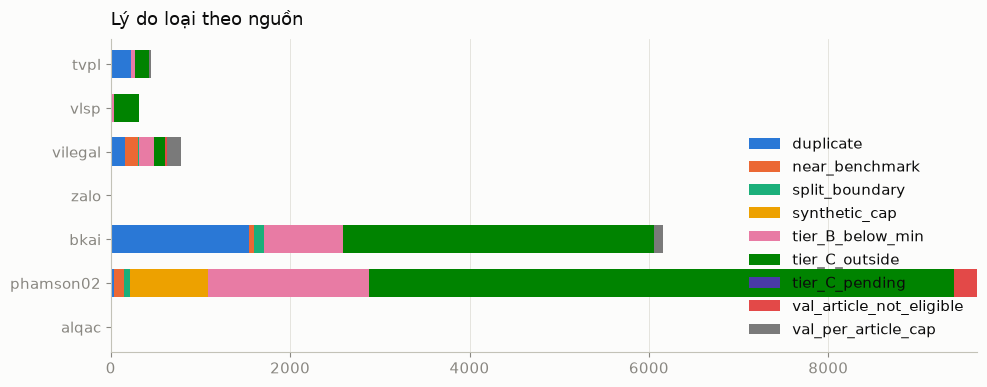

In [5]:
rej = stages[stages.index.str.startswith("rejected:")].copy()
rej.index = rej.index.str.replace("rejected:", "", regex=False)
rej["tổng"] = rej.sum(axis=1)
display(rej.sort_values("tổng", ascending=False))
stacked_barh(rej.drop(columns="tổng").T, "Lý do loại theo nguồn", colors=CAT + ["#7a7a7a", "#b0b0b0"], figsize=(10, 4))

## 4. Kết quả và kiểm chứng

In [6]:
t, v, chk = report["train"], report["val"], report["checks"]
print(f"TRAIN: {t['total']} câu | tỉ lệ câu sinh {t['synthetic_ratio']} | {t['chunks_covered']} chunk, "
      f"{t['articles_covered']} Điều | benchmark v3 gold phủ {t['benchmark_v3_gold_covered']}")
print(f"VAL:   {v['total']} câu, {v['articles']} Điều")
display(pd.DataFrame({"train": t["by_source"], "val": v["by_source"]}).fillna(0).astype(int))
display(pd.DataFrame({"chunk train": t["by_de_muc"], "câu val": v["by_de_muc"]}).fillna(0).astype(int)
        .loc[lambda d: d.index.str.match(r"^20\.\d$")])
print("tier:", t["by_tier"], "| temporal:", t["by_temporal"])

assert chk["train_val_article_overlap"] == 0, "train/val dùng chung Điều"
assert chk["near_benchmark_left"] == 0, "còn câu gần trùng benchmark"
assert chk["synthetic_ratio_ok"], "vượt giới hạn câu sinh"
print("Kiểm chứng: OK", chk)

TRAIN: 7118 câu | tỉ lệ câu sinh 0.4 | 956 chunk, 915 Điều | benchmark v3 gold phủ 274/345
VAL:   174 câu, 62 Điều


,train,val
alqac,53,6
bkai,1359,26
phamson02,2847,0
tvpl,133,1
vilegal,2713,140
zalo,13,1


,chunk train,câu val
20.4,238,29
20.5,167,16
20.2,406,105
20.3,144,24


tier: {'A': 6549, 'B': 569} | temporal: {'keep': 6870, 'remap': 248}
Kiểm chứng: OK {'train_val_article_overlap': 0, 'near_benchmark_left': 0, 'synthetic_ratio_ok': True}


### Đọc mẫu 20 cặp train

Câu hỏi → Điều được gán làm đoạn đúng (text chunk v5).

In [7]:
chunks = {c["chunk_id"]: c for c in load_jsonl(LAO_DONG_DIR / "chunks.jsonl")}
train_q = load_jsonl(FINETUNE_MERGED_DIR / "queries_train.jsonl")
sample = pd.DataFrame([
    {"nguồn": r["source"], "tier": r["tier"], "score": r["score"], "câu hỏi": r["query"][:100],
     "Điều": chunks[r["chunk_id"]]["text"].split("\n")[1][:70], "chunk": r["chunk_id"]}
    for r in random.Random(7).sample(train_q, 20)
])
sample

,nguồn,tier,score,câu hỏi,Điều,chunk
0,phamson02,A,0.6919,"Người sử dụng lao động có được gây khó khăn, cản trở hoặc can thiệp vào quá trình tổ chức đại diện n",Điều 202. Quyết định đình công và thông báo thời điểm bắt đầu đình côn,45-2019-qh14:d202
1,bkai,B,0.3423,Công ty giam lương của người lao động để đảm bảo nghĩa vụ bồi thường do đơn phương chấm dứt hợp đồng,Điều 94. Nguyên tắc trả lương,45-2019-qh14:d94
2,phamson02,A,1.0000,Bộ Y tế quy định thế nào về giấy chứng nhận đủ sức khỏe cho người lao động đi làm việc ở nước ngoài?,Điều 45. Hồ sơ của người lao động đi làm việc ở nước ngoài,69-2020-qh14:d45
3,vilegal,A,0.9459,Hợp đồng lao động giữa người lao động và người sử dụng lao động được quy định ra sao?,Điều 13. Hợp đồng lao động,45-2019-qh14:d13
4,bkai,A,0.7907,Khám phát hiện bệnh nghề nghiệp cần hồ sơ gồm những gì?,Điều 1. Phạm vi Điều chỉnh,44-2016-nd-cp:d1
5,bkai,A,1.0000,Một năm người lao động có bao nhiêu ngày nghỉ phép?,Điều 113. Nghỉ hằng năm,45-2019-qh14:d113
6,vilegal,A,0.9773,Doanh nghiệp có được trả lương cho người lao động thấp hơn mức lương tối thiểu vùng không?,Điều 90. Tiền lương,45-2019-qh14:d90
7,tvpl,A,1.0000,Người sử dụng lao động trả lương cho người lao động dựa trên những căn cứ nào?,Điều 95. Trả lương,45-2019-qh14:d95
8,bkai,A,1.0000,"Sau lễ Quốc khánh 2/9 thì người lao động còn được nghỉ thêm ngày lễ, tết nào không?","Điều 112. Nghỉ lễ, tết",45-2019-qh14:d112
9,phamson02,A,0.8657,"Trong trường hợp có nguy cơ trực tiếp gây sự cố, tai nạn lao động, an toàn, vệ sinh viên có quyền yê","Điều 74. An toàn, vệ sinh viên",84-2015-qh13:d74


## 5. Hard negative + ghép train.jsonl (cần GPU)

`mine_negatives` lấy top-30 chunk gần nhất theo BGE-M3 gốc, bỏ chunk cùng Điều với đoạn đúng và các Điều có quan hệ `REFERS_TO` (tránh false negative), giữ 5. Sau đó `assemble_dataset` ghép thành `train.jsonl` / `val.jsonl` cho notebook 03. Không đào thì `train.jsonl` vẫn được ghép (không có negatives → chỉ chạy được giai đoạn 1).

In [8]:
if RUN_MINING:
    run("labor_rag.finetune.mine_negatives", "--top-k", "30", "--neg-k", "5")
from labor_rag.finetune.assemble_dataset import assemble_from_queries
stats = assemble_from_queries()
stats

Saved 7118 training samples to D:\Work\Learn\HK7_2026-2027\PBL6\data\processed\finetune\merged\train.jsonl and 174 validation queries to D:\Work\Learn\HK7_2026-2027\PBL6\data\processed\finetune\merged\val.jsonl


{'created_at': '2026-10-19T12:42:41.319601+00:00',
 'total_train_samples': 7118,
 'by_type': {'real_query': 4271, 'synthetic_query': 2847},
 'by_source': {'alqac': 53,
  'bkai': 1359,
  'phamson02': 2847,
  'tvpl': 133,
  'vilegal': 2713,
  'zalo': 13},
 'kg_pair_samples': 0,
 'samples_with_hard_negatives': 0,
 'validation_queries': 174,
 'corpus_chunks_count': 1481}

In [9]:
for p in sorted(FINETUNE_MERGED_DIR.glob("*")):
    print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1e6:.2f} MB)")

data\processed\finetune\merged\build_report.json  (0.00 MB)
data\processed\finetune\merged\dataset_stats.json  (0.00 MB)
data\processed\finetune\merged\queries_train.jsonl  (2.72 MB)
data\processed\finetune\merged\queries_val.jsonl  (0.04 MB)
data\processed\finetune\merged\rejected.jsonl  (4.31 MB)
data\processed\finetune\merged\train.jsonl  (17.79 MB)
data\processed\finetune\merged\val.jsonl  (0.05 MB)
